# S2 · Within-voxel MRS/H correlations

In [1]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
df = pd.read_csv(f"{base_path}/DATA/discovery_dataset/20260529_101516_WAND_ses-05_GANNET_MRS_results.csv")

In [4]:
from scipy import stats

MRS_path = f"{base_path}/DATA/discovery_dataset/cleaned_MRS_df.csv"
hurst_path = f"{base_path}/RESULTS/discovery_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
selected_parcels = f"{base_path}/DATA/discovery_dataset/selected_parcels_overlap30.csv"

MRS_path_DLPFC = f"{base_path}/DATA/replication_dataset/EIB_12s_MRS_static_&_AUC_New_criteria.csv"
hurst_path_DLPFC = f"{base_path}/RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
selected_parcels_DLPFC = f"{base_path}/DATA/replication_dataset/selected_parcels_overlap30.csv"
output_path = f"{base_path}/FIGURES/supplementary/Fig_S2"
os.makedirs(output_path, exist_ok=True)

mrs_df = pd.read_csv(MRS_path)
hurst_df = pd.read_csv(hurst_path)
selected_df = pd.read_csv(selected_parcels)

mrs_df_DLPFC = pd.read_csv(MRS_path_DLPFC)
hurst_df_DLPFC = pd.read_csv(hurst_path_DLPFC)
selected_df_DLPFC = pd.read_csv(selected_parcels_DLPFC)

In [5]:
display(mrs_df.head())
display(hurst_df.head())
display(selected_df.head())

,Subject,Voxel,GABA_ConcIU_TissCorr,GABA_ConcIU_AlphaTissCorr,Glx_ConcIU_TissCorr,Glx_ConcIU_AlphaTissCorr,GlxGABA_TissCorr,GlxGABA_AlphaTissCorr,GABA_FWHM,GABA_SNR,GABA_FitError,Glx_FWHM,Glx_SNR,Glx_FitError,fGM,WaterSuppFactor,Status,GABA_eligible,Glx_eligible,Overall_eligible
0,sub-01187,anteriorcingulate,5.760785,5.540606,18.2019609706534+0i,17.506277,3.15963201501128+0i,3.159632,21.390905,40.748813,4.092103,13.275370,57.394370,2.913208,0.417790,NaN,ok,True,True,True
1,sub-01187,occipital,7.863402,6.791862,20.1005986241487+0i,17.361505,2.55622159928783+0i,2.556222,22.276577,45.863883,3.252277,14.355305,51.351994,2.850017,0.671500,NaN,ok,True,True,True
2,sub-01187,rightauditory,6.114164,5.578763,16.7777991478426+0i,15.308613,2.74408731655244+0i,2.744087,21.782348,27.439589,2.063005,16.475108,28.087600,2.419095,0.556615,NaN,ok,True,True,True
3,sub-01187,smleft,6.010018,6.599470,15.3205169571664+0i,16.823127,2.54916329873825+0i,2.549163,20.831409,31.499919,3.866499,14.218438,33.769208,4.260142,0.226813,NaN,ok,True,True,True
4,sub-04843,anteriorcingulate,6.264310,5.678181,21.5652010990074+0i,19.547425,3.44255037627957+0i,3.442550,21.274529,40.735091,4.386073,12.784429,64.315855,3.164467,0.528583,NaN,ok,True,True,True


,Hursts,Subject,Parcel,Network
0,0.937274,sub-00395,1,Vis
1,1.132754,sub-00395,2,Vis
2,1.399384,sub-00395,3,Vis
3,1.066653,sub-00395,4,Vis
4,1.340076,sub-00395,5,Vis


,voxel,parcel_id,fraction_of_parcel,selected_30perc_of_voxel,mask_file
0,anteriorcingulate,28,0.796226,True,C:/Users/matil/Desktop/Hurst/DATA/WAND/group_m...
1,anteriorcingulate,88,0.792239,True,C:/Users/matil/Desktop/Hurst/DATA/WAND/group_m...
2,anteriorcingulate,78,0.324000,True,C:/Users/matil/Desktop/Hurst/DATA/WAND/group_m...
3,occipital,49,0.445045,True,C:/Users/matil/Desktop/Hurst/DATA/WAND/group_m...
4,occipital,100,0.437118,True,C:/Users/matil/Desktop/Hurst/DATA/WAND/group_m...


Voxel: ACC (n=148)
  Pearson: r = 0.048, p = 0.566
  Spearman: rho = 0.072, p = 0.382

Voxel: OCC (n=147)
  Pearson: r = -0.015, p = 0.854
  Spearman: rho = -0.026, p = 0.758

Voxel: rAUD (n=131)
  Pearson: r = -0.009, p = 0.916
  Spearman: rho = -0.015, p = 0.867

Voxel: lSMN (n=150)
  Pearson: r = -0.039, p = 0.64
  Spearman: rho = -0.044, p = 0.597

Voxel: lDLPFC
  Pearson: r = 0.011, p = 0.958
  Spearman: rho = 0.081, p = 0.707


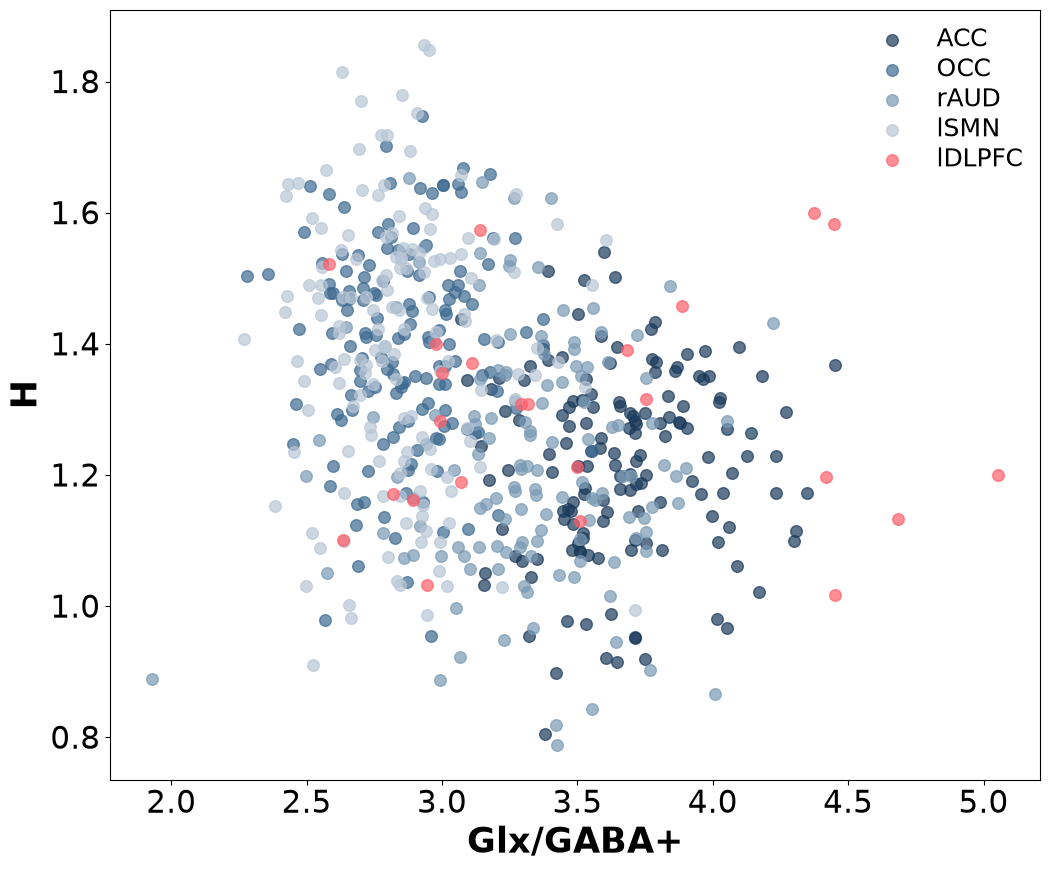

In [6]:
voxels = np.unique(selected_df["voxel"].values)

labels = {
    "anteriorcingulate": "ACC",
    "occipital": "OCC",
    "rightauditory": "rAUD",
    "smleft": "lSMN",
    }

colors = {
    "smleft": "#b8c6d6",
    "rightauditory": "#7a9ab5",
    "occipital": "#3d6a91",
    "anteriorcingulate": "#1a3a5c",
}

plt.figure(figsize=(12, 10))
for vx in voxels:
    selected_parcels = selected_df[selected_df["voxel"] == vx]["parcel_id"].values
    hurst_voxel_df = hurst_df[hurst_df["Parcel"].isin(selected_parcels)].copy()
    mrs_voxel_df = mrs_df[mrs_df["Voxel"] == vx].copy()
    merged_df = hurst_voxel_df.merge(mrs_voxel_df, on="Subject", how="inner")
    merged_df = merged_df.dropna(subset=["Hursts", "GlxGABA_AlphaTissCorr"]).copy()

    merged_df = (
        merged_df.groupby("Subject", as_index=False)[["Hursts", "GlxGABA_AlphaTissCorr"]]
        .mean()
    )
   
    pearson_r, pearson_p = stats.pearsonr(merged_df["GlxGABA_AlphaTissCorr"], merged_df["Hursts"])
    spearman_rho, spearman_p = stats.spearmanr(merged_df["GlxGABA_AlphaTissCorr"], merged_df["Hursts"])

    print(f"Voxel: {labels.get(vx, vx)} (n={len(merged_df)})")
    print(f"  Pearson: r = {pearson_r:.3f}, p = {pearson_p:.3g}")
    print(f"  Spearman: rho = {spearman_rho:.3f}, p = {spearman_p:.3g}")
    print()
    plt.scatter(
        merged_df["GlxGABA_AlphaTissCorr"],
        merged_df["Hursts"],
        alpha=0.7,
        s=70,
        c=colors.get(vx),
        label=f"{labels.get(vx, vx)}"
    )


selected_parcels =  [26, 27, 35, 43, 45]
hurst_voxel_df = hurst_df_DLPFC[hurst_df_DLPFC["Parcel"].isin(selected_parcels)].copy()
mrs_voxel_df = mrs_df_DLPFC.copy()
merged_df = hurst_voxel_df.merge(mrs_voxel_df, on="Subject", how="inner")
merged_df = merged_df.dropna(subset=["Hursts", "EIB"]).copy()

merged_df = (
    merged_df.groupby("Subject", as_index=False)[["Hursts", "EIB"]]
    .mean()
)

pearson_r, pearson_p = stats.pearsonr(merged_df["EIB"], merged_df["Hursts"])
spearman_rho, spearman_p = stats.spearmanr(merged_df["EIB"], merged_df["Hursts"])
plt.scatter(
    merged_df["EIB"],
    merged_df["Hursts"],
    alpha=0.7,
    s=70,
    c='#ff5e69',
    label=f"lDLPFC"
)

print(f"Voxel: lDLPFC")
print(f"  Pearson: r = {pearson_r:.3f}, p = {pearson_p:.3f}")
print(f"  Spearman: rho = {spearman_rho:.3f}, p = {spearman_p:.3f}")

plt.legend(frameon=False, fontsize=18, markerscale=1, borderpad=0.2, labelspacing=0.2)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.xlabel("Glx/GABA+", fontsize=25, fontweight="bold")
plt.ylabel("H", fontsize=25, fontweight="bold")

plt.savefig(f"{output_path}/voxel_correlations.png", dpi=300, bbox_inches="tight")